# Dopamine D2 workflow: fingerprints and model training/validation

Run all cells from top to bottom. Step 1 reads the curated D2 compounds from `data/raw/`, encodes
MACCS / Morgan fingerprints, and writes the fingerprint CSVs to `data/processed/`. Step 2 benchmarks
RF, SVR and ANN regressors, saves figures and metric tables under `results/`, and stores the final
model under `models/`.

1. Global Setup and Project Information
Aim: To build, evaluate, and select a robust Quantitative Structure-Activity Relationship (QSAR) model capable of predicting the binding affinity (pIC50) of novel DRD2 antagonists based on their chemical structures.

Software and Packages Used:
Python 
`scikit-learn` (1.9.1): RandomForestRegressor, SVR, MLPRegressor, KFold, train_test_split, metrics.
`rdkit` (2026.3.6): MACCS keys and Morgan fingerprints.
`pandas` (3.0.6), `numpy` (2.5.3), `matplotlib` (3.11.1)
`joblib` (1.6.0): saves the final model. `tqdm` (4.70.0): progress bars.
Standard library: `pathlib`, `random`, `time`.


Global Settings & Parameters:
`N_BITS = 2048`: Dimensionality for Morgan fingerprints to minimize bit collisions.
`SEED = 22`: Ensures reproducibility across all random train/test splits and model initializations.
`TEST_SIZE = 0.2`: 20% of the data is held out for the single-split validation to ensure sufficient training data (80%) while maintaining a reliable test set.
`N_FOLDS = 5`: Used for K-Fold cross-validation to provide statistically robust performance metrics.
`ACTIVITY_CUTOFF = 6.3`: Threshold used to optionally binarize pIC50 into active/inactive classes.

Required Input Files:
`data/raw/drd2_curated_compounds.csv`: The cleaned target data generated in Step 1.

In [1]:
# Install the packages needed for this notebook (only needed once per environment)
%pip install rdkit scikit-learn joblib tqdm matplotlib pandas

Note: you may need to restart the kernel to use updated packages.


In [2]:
import random
import time
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from tqdm.auto import tqdm

from rdkit import Chem
from rdkit.Chem import MACCSkeys, rdFingerprintGenerator

from sklearn import clone
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import KFold, train_test_split
from sklearn.neural_network import MLPRegressor
from sklearn.svm import SVR

In [3]:
# Find the repository root so paths work from the project root or src/.
PROJECT_ROOT = Path.cwd().resolve()
while not (PROJECT_ROOT / ".git").exists():
    if PROJECT_ROOT.parent == PROJECT_ROOT:
        raise RuntimeError("Could not locate the project root (expected a .git directory).")
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_DIR = PROJECT_ROOT / "data" / "processed"
FIGURES_DIR = PROJECT_ROOT / "results" / "figures"
TABLES_DIR = PROJECT_ROOT / "results" / "tables"
MODEL_DIR = PROJECT_ROOT / "models"
CSV_PATH = PROJECT_ROOT / "data" / "raw" / "drd2_curated_compounds.csv"
for output_dir in (DATA_DIR, FIGURES_DIR, TABLES_DIR, MODEL_DIR):
    output_dir.mkdir(parents=True, exist_ok=True)
ACTIVITY_CUTOFF = 6.3  # pIC50 cutoff used in T007 (optional labeling)
N_BITS = 2048
FINGERPRINTS = ("maccs", "morgan2", "morgan3")
SEED = 22
TEST_SIZE = 0.2
N_FOLDS = 5

random.seed(SEED)
np.random.seed(SEED)

# Step 1: Encode SMILES as fingerprints

Encode SMILES from `data/raw/drd2_curated_compounds.csv` as fingerprints (MACCS, Morgan radius 2, Morgan radius 3),
following TeachOpenCADD T007. One CSV per fingerprint is written to `data/processed/` and read again in Step 2.

2. Molecular Encoding (Fingerprint Generation)
Purpose: Convert SMILES strings into numeric bit vectors so that machine learning algorithms can mathematically process structural features.

In [ ]:
# Generators are created once and reused
_MORGAN_GENERATORS = {
    "morgan2": rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=N_BITS),
    "morgan3": rdFingerprintGenerator.GetMorganGenerator(radius=3, fpSize=N_BITS),
}


def smiles_to_fp(smiles, method="maccs"):
    """
    Encode a SMILES string as a numpy fingerprint array.
    
    Args:
        smiles (str): SMILES string of the target molecule.
        method (str): "maccs" (166 bits), "morgan2" or "morgan3" (2048 bits).
        
    Returns:
        np.ndarray or None: Computed fingerprint, or None if RDKit cannot parse the SMILES.
    """
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        return None
    if method == "maccs":
        return np.array(MACCSkeys.GenMACCSKeys(mol))
    if method in _MORGAN_GENERATORS:
        return _MORGAN_GENERATORS[method].GetFingerprintAsNumPy(mol)
    raise ValueError(f"Unknown method: {method}")


def drop_invalid_smiles(df):
    """
    Remove rows from the dataset containing SMILES that RDKit cannot parse to prevent training errors.
    
    Args:
        df (pd.DataFrame): The input dataframe containing a 'smiles' column.
        
    Returns:
        pd.DataFrame: Cleaned dataframe with invalid SMILES dropped.
    """
    valid = df["smiles"].apply(lambda smi: Chem.MolFromSmiles(smi) is not None)
    if not valid.all():
        print(f"Dropped {(~valid).sum()} molecules with invalid SMILES")
    return df[valid].reset_index(drop=True)


def fingerprint_matrix(smiles_series, method):
    """
    Generate the full feature matrix for a specific fingerprint methodology.
    
    Args:
        smiles_series (pd.Series): A sequence of SMILES strings.
        method (str): The fingerprinting algorithm to utilize.
        
    Returns:
        np.ndarray: An (n_molecules, n_bits) feature matrix for machine learning.
    """
    fps = [smiles_to_fp(smi, method) for smi in tqdm(smiles_series, desc=method)]
    return np.stack(fps)

In [5]:
fp_df = pd.read_csv(CSV_PATH)[["smiles", "pIC50"]]
print("Shape:", fp_df.shape)

# Activity label (as in T007)
fp_df["active"] = (fp_df["pIC50"] >= ACTIVITY_CUTOFF).astype(float)
fp_df = drop_invalid_smiles(fp_df)

# One CSV per fingerprint: bit columns, then smiles, pIC50, active
for method in ("maccs", "morgan2", "morgan3"):
    X_fp = fingerprint_matrix(fp_df["smiles"], method)
    first_bit = 0
    if method == "maccs":
        X_fp = X_fp[:, 1:]  # RDKit MACCS bit 0 is unused (always 0)
        first_bit = 1  # keep original key numbering: bit_1 ... bit_166
    out = pd.DataFrame(
        X_fp, columns=[f"bit_{i}" for i in range(first_bit, first_bit + X_fp.shape[1])]
    )
    out["smiles"] = fp_df["smiles"]
    out["pIC50"] = fp_df["pIC50"]
    out["active"] = fp_df["active"]
    out_path = DATA_DIR / f"DopamineD2_{method}.csv"
    out.to_csv(out_path, index=False)
    print(f"{method}: {X_fp.shape} -> {out_path}")

Shape: (435, 2)


maccs:   0%|          | 0/435 [00:00<?, ?it/s]

maccs: (435, 166) -> C:\Users\manup\Documents\Leiden Universiteit\LUMC\Advanced Computational Methods in Drug Discovery\Mini-Research\drd2-antagonist-ml-docking\data\processed\DopamineD2_maccs.csv


morgan2:   0%|          | 0/435 [00:00<?, ?it/s]

morgan2: (435, 2048) -> C:\Users\manup\Documents\Leiden Universiteit\LUMC\Advanced Computational Methods in Drug Discovery\Mini-Research\drd2-antagonist-ml-docking\data\processed\DopamineD2_morgan2.csv


morgan3:   0%|          | 0/435 [00:00<?, ?it/s]

morgan3: (435, 2048) -> C:\Users\manup\Documents\Leiden Universiteit\LUMC\Advanced Computational Methods in Drug Discovery\Mini-Research\drd2-antagonist-ml-docking\data\processed\DopamineD2_morgan3.csv


# Step 2: Machine learning: predicting pIC50 (regression)

Regression of pIC50 for dopamine D2 compounds from fingerprints.

Reads the fingerprint CSVs written in Step 1,
trains RF, SVR and ANN regressors, and evaluates them with a single train/test split
(predicted vs. measured plots) and k-fold cross-validation. At the end, the best model is
fit on all compounds and saved, so new datasets can be predicted without retraining.

(Imports and settings for this part are in the setup cells at the top of the notebook.)

## Models and helper functions

3. Model Definition and Cross-Validation
Purpose: Systematically train and validate regression models to identify the best algorithm-fingerprint pair for predicting binding affinity.

In [ ]:
def get_models():
    """
    Return fresh, uninitialized regression models.
    
    Returns:
        dict: A dictionary mapping model names to their scikit-learn instances.
    """
    return {
        "RF": RandomForestRegressor(n_estimators=100, random_state=SEED),
        "SVR": SVR(kernel="rbf", C=1.0, gamma="scale"),
        "ANN": MLPRegressor(hidden_layer_sizes=(64, 32), random_state=SEED, max_iter=2000),
    }


def load_fingerprint_data(method):
    """"
    Load feature matrix X and target vector y from a processed fingerprint CSV.
    
    Args:
        method (str): The fingerprinting method corresponding to the filename.
        
    Returns:
        tuple: (X_matrix, y_vector) as numpy arrays.
    """
    df = pd.read_csv(DATA_DIR / f"DopamineD2_{method}.csv")
    bit_cols = [c for c in df.columns if c.startswith("bit_")]
    return df[bit_cols].to_numpy(dtype=float), df["pIC50"].to_numpy()


def regression_metrics(y_true, y_pred):
    """
    Calculate standard regression performance metrics.
    
    Args:
        y_true (np.ndarray): Actual measured pIC50 values.
        y_pred (np.ndarray): Model-predicted pIC50 values.
        
    Returns:
        dict: Dictionary containing RMSE, MAE, R-squared, and Pearson correlation.
    """
    return {
        "rmse": np.sqrt(mean_squared_error(y_true, y_pred)),
        "mae": mean_absolute_error(y_true, y_pred),
        "r2": r2_score(y_true, y_pred),
        "pearson_r": np.corrcoef(y_true, y_pred)[0, 1],
    }

## Single train/test split

Train all models on one 80/20 split and plot predicted vs. measured pIC50.

In [ ]:
def single_split_evaluation(method, X, y):
    """"
    Train models on a single 80/20 split and generate correlation scatter plots.
    
    Args:
        method (str): Fingerprint method name used for plot titling.
        X (np.ndarray): Feature matrix.
        y (np.ndarray): Target vector.
        
    Returns:
        list: Evaluation metrics mapped to the respective models.
    """
    train_x, test_x, train_y, test_y = train_test_split(
        X, y, test_size=TEST_SIZE, random_state=SEED
    )
    models = get_models()
    fig, axes = plt.subplots(1, len(models), figsize=(4 len(models), 4), sharex=True, sharey=True)
    rows = []
    for ax, (name, model) in zip(axes, models.items()):
        model.fit(train_x, train_y)
        pred = model.predict(test_x)
        res = regression_metrics(test_y, pred)
        rows.append({"fingerprint": method, "model": name, res})
        ax.scatter(test_y, pred, s=12, alpha=0.7)
        lims = [min(y.min(), pred.min()), max(y.max(), pred.max())]
        ax.plot(lims, lims, "r--")
        ax.set_title(f"{name} (R² = {res['r2']:.2f}, RMSE = {res['rmse']:.2f})")
        ax.set_xlabel("Measured pIC50")
    axes[0].set_ylabel("Predicted pIC50")
    fig.suptitle(method)
    fig.savefig(FIGURES_DIR / f"pred_vs_measured_{method}.png", dpi=300, bbox_inches="tight")
    plt.show()
    return rows

## K-fold cross-validation

In [ ]:
def crossvalidation(method, X, y, n_folds=N_FOLDS):
    """"
    Execute K-Fold cross validation to calculate mean performance metrics.
    
    Args:
        method (str): Fingerprint method name.
        X (np.ndarray): Feature matrix.
        y (np.ndarray): Target vector.
        n_folds (int): Number of folds for splitting.
        
    Returns:
        list: Aggregated mean and standard deviation metrics for each model.
    """
    kf = KFold(n_splits=n_folds, shuffle=True, random_state=SEED)
    rows = []
    for name, model in get_models().items():
        t0 = time.time()
        folds = []
        for train_idx, test_idx in kf.split(X):
            fold_model = clone(model)  # fresh copy per fold
            fold_model.fit(X[train_idx], y[train_idx])
            folds.append(regression_metrics(y[test_idx], fold_model.predict(X[test_idx])))
        fold_df = pd.DataFrame(folds)
        row = {"fingerprint": method, "model": name}
        for col in fold_df:
            row[f"{col}_mean"] = fold_df[col].mean()
            row[f"{col}_std"] = fold_df[col].std(ddof=0)
        row["time_s"] = time.time() - t0
        rows.append(row)
    return rows

## Run the evaluation for all fingerprints

maccs: X = (435, 166), pIC50 range = 4.00-9.52


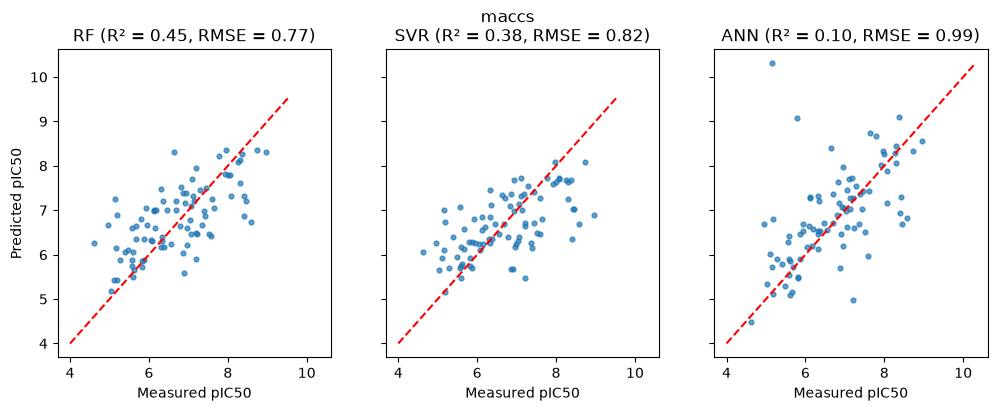

morgan2: X = (435, 2048), pIC50 range = 4.00-9.52


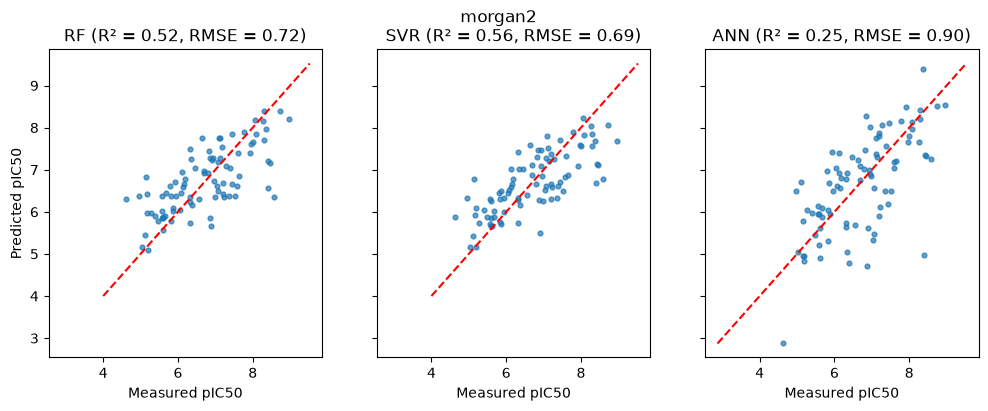

morgan3: X = (435, 2048), pIC50 range = 4.00-9.52


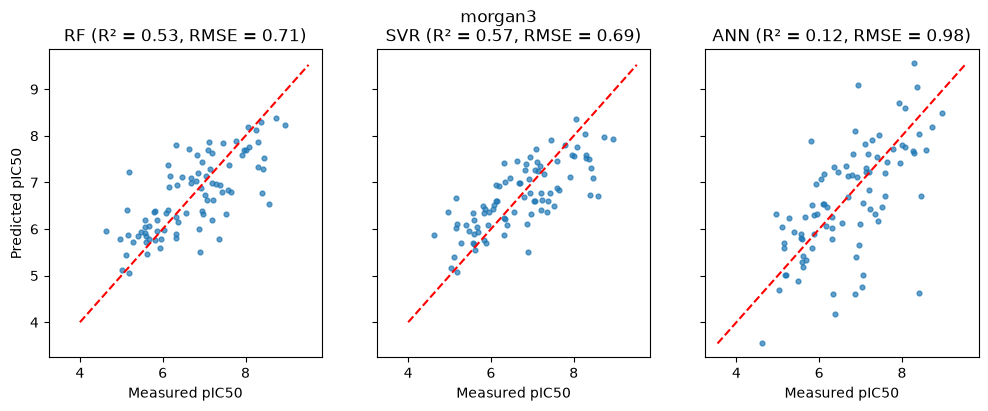

In [9]:
split_rows, cv_rows = [], []
for method in FINGERPRINTS:
    X, y = load_fingerprint_data(method)
    print(f"{method}: X = {X.shape}, pIC50 range = {y.min():.2f}-{y.max():.2f}")
    split_rows += single_split_evaluation(method, X, y)
    cv_rows += crossvalidation(method, X, y)

split_df = pd.DataFrame(split_rows)
cv_df = pd.DataFrame(cv_rows)
split_df.to_csv(TABLES_DIR / "reg_results_single_split.csv", index=False)
cv_df.to_csv(TABLES_DIR / "reg_results_crossvalidation.csv", index=False)

In [10]:
print("Single train/test split")
split_df.round(2)

Single train/test split


,fingerprint,model,rmse,mae,r2,pearson_r
0,maccs,RF,0.77,0.61,0.45,0.68
1,maccs,SVR,0.82,0.63,0.38,0.62
2,maccs,ANN,0.99,0.64,0.10,0.57
3,morgan2,RF,0.72,0.57,0.52,0.72
4,morgan2,SVR,0.69,0.55,0.56,0.75
5,morgan2,ANN,0.90,0.70,0.25,0.66
6,morgan3,RF,0.71,0.56,0.53,0.73
7,morgan3,SVR,0.69,0.56,0.57,0.76
8,morgan3,ANN,0.98,0.73,0.12,0.63


In [11]:
print(f"{N_FOLDS}-fold cross-validation")
cv_df.round(2)

5-fold cross-validation


,fingerprint,model,rmse_mean,rmse_std,mae_mean,mae_std,r2_mean,r2_std,pearson_r_mean,pearson_r_std,time_s
0,maccs,RF,0.87,0.07,0.68,0.05,0.36,0.07,0.61,0.05,1.73
1,maccs,SVR,0.88,0.03,0.67,0.03,0.34,0.04,0.60,0.03,0.06
2,maccs,ANN,1.09,0.11,0.78,0.09,-0.02,0.22,0.49,0.10,4.48
3,morgan2,RF,0.77,0.03,0.60,0.03,0.49,0.04,0.71,0.03,7.57
4,morgan2,SVR,0.76,0.04,0.59,0.04,0.51,0.05,0.72,0.03,0.35
5,morgan2,ANN,1.02,0.09,0.77,0.05,0.10,0.17,0.63,0.05,23.14
6,morgan3,RF,0.76,0.04,0.59,0.04,0.51,0.05,0.72,0.03,19.45
7,morgan3,SVR,0.76,0.05,0.60,0.04,0.50,0.05,0.72,0.04,0.89
8,morgan3,ANN,1.11,0.12,0.82,0.05,-0.06,0.28,0.59,0.08,24.82


## Final model for prediction on new datasets

The evaluation above fits a new model for every split and fold and throws it away afterwards.
To predict new compounds, we pick the best combination from the cross-validation
(highest R², lowest RMSE), fit it once on all compounds, and save it to disk.

4. Final Model Selection and Deployment
Purpose: Deploy the superior model to infer activities of unseen molecules.

In [12]:
# Best combination in the cross-validation above (highest R², lowest RMSE)
FINAL_MODEL = "SVR"
FINAL_FINGERPRINT = "morgan2"
FINAL_MODEL_PATH = MODEL_DIR / f"final_{FINAL_MODEL.lower()}_{FINAL_FINGERPRINT}.joblib"

In [ ]:
def train_final_model():
    """
    Fit the winning model architecture on ALL curated compounds to maximize 
    predictive domain knowledge, and save it to disk.
    
    Returns:
        model: The fitted scikit-learn model.
    """
    X, y = load_fingerprint_data(FINAL_FINGERPRINT)
    model = get_models()[FINAL_MODEL].fit(X, y)
    joblib.dump(model, FINAL_MODEL_PATH)
    print(f"Final {FINAL_MODEL} ({FINAL_FINGERPRINT}) fit on {len(y)} compounds -> {FINAL_MODEL_PATH}")
    return model


final_model = train_final_model()

Final SVR (morgan2) fit on 435 compounds -> C:\Users\manup\Documents\Leiden Universiteit\LUMC\Advanced Computational Methods in Drug Discovery\Mini-Research\drd2-antagonist-ml-docking\models\final_svr_morgan2.joblib


## Predict pIC50 for a new dataset (no retraining)

`predict_pic50` loads the saved model and encodes the new SMILES with the same
fingerprint as the training data. Once the model is saved, only the settings cell,
the imports and this cell are needed to predict a new dataset.

In [ ]:
def predict_pic50(smiles_list, model_path=FINAL_MODEL_PATH):
    """
    Predict pIC50 and back-calculate IC50 (nM) for novel SMILES strings 
    using the pre-trained, serialized model.
    
    Args:
        smiles_list (list): List of novel SMILES strings to evaluate.
        model_path (Path): Path to the saved .joblib model.
        
    Returns:
        pd.DataFrame: Table of predictions including SMILES, pIC50, and IC50 (nM).
    """
    model = joblib.load(model_path)
    rows = []
    for smi in smiles_list:
        fp = smiles_to_fp(smi, FINAL_FINGERPRINT)  # same featurisation as the training data
        if fp is None:  # SMILES RDKit cannot parse
            rows.append({"smiles": smi, "pred_pIC50": np.nan, "pred_IC50_nM": np.nan})
            continue
        if FINAL_FINGERPRINT == "maccs":
            fp = fp[1:]  # training data dropped MACCS bit 0
        pic50 = model.predict(fp.reshape(1, -1).astype(float))[0]
        rows.append({"smiles": smi, "pred_pIC50": pic50, "pred_IC50_nM": 10  (9 - pic50)})
    return pd.DataFrame(rows)

In [15]:
# Example: predict a few SMILES. For a dataset, use e.g.
# new_df = pd.read_csv("path/to/new_dataset.csv")
# predictions = predict_pic50(new_df["smiles"])
example_smiles = [
    "OCCN1CCN(CCCN2c3ccccc3Sc3ccc(Cl)cc32)CC1",                # CHEMBL567, measured pIC50 9.52
    "CC1=C(C(=O)N2CCCCC2=N1)CCN3CCN(CC3)C4=CC=CC5=C4C=CN5",    # similarity-search hit
]
predict_pic50(example_smiles)

,smiles,pred_pIC50,pred_IC50_nM
0,OCCN1CCN(CCCN2c3ccccc3Sc3ccc(Cl)cc32)CC1,8.097969,7.980516
1,CC1=C(C(=O)N2CCCCC2=N1)CCN3CCN(CC3)C4=CC=CC5=C...,7.784896,16.409822
